In [1]:
# 0. Setup and load the Iris dataset
# If needed, install packages in a notebook cell with:
# %pip install pandas numpy matplotlib seaborn scikit-learn scipy

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.cluster import KMeans
from sklearn.metrics import (
    mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, silhouette_score
)
from sklearn.metrics import pairwise_distances
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

DATA_PATH = "iris.csv"
if not os.path.exists(DATA_PATH) and os.path.exists("/mnt/data/iris.csv"):
    DATA_PATH = "/mnt/data/iris.csv"

df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())
print("\nColumn names:", df.columns.tolist())
print("\nMissing values per column:")
print(df.isnull().sum())

# This notebook expects four numeric measurement columns and one species/label column.
feature_cols = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
target_col = "species"

# If your column names differ, edit feature_cols and target_col above.
X = df[feature_cols].copy()
y = df[target_col].astype(str).copy()

print("\nSpecies counts:")
print(y.value_counts())


Dataset shape: (150, 5)

First 5 rows:


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa



Column names: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']

Missing values per column:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Species counts:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


Slope: 1.8328
Intercept: -6.9198
MAE: 0.6168
MSE: 0.5965
RMSE: 0.7723
R² score: 0.8180


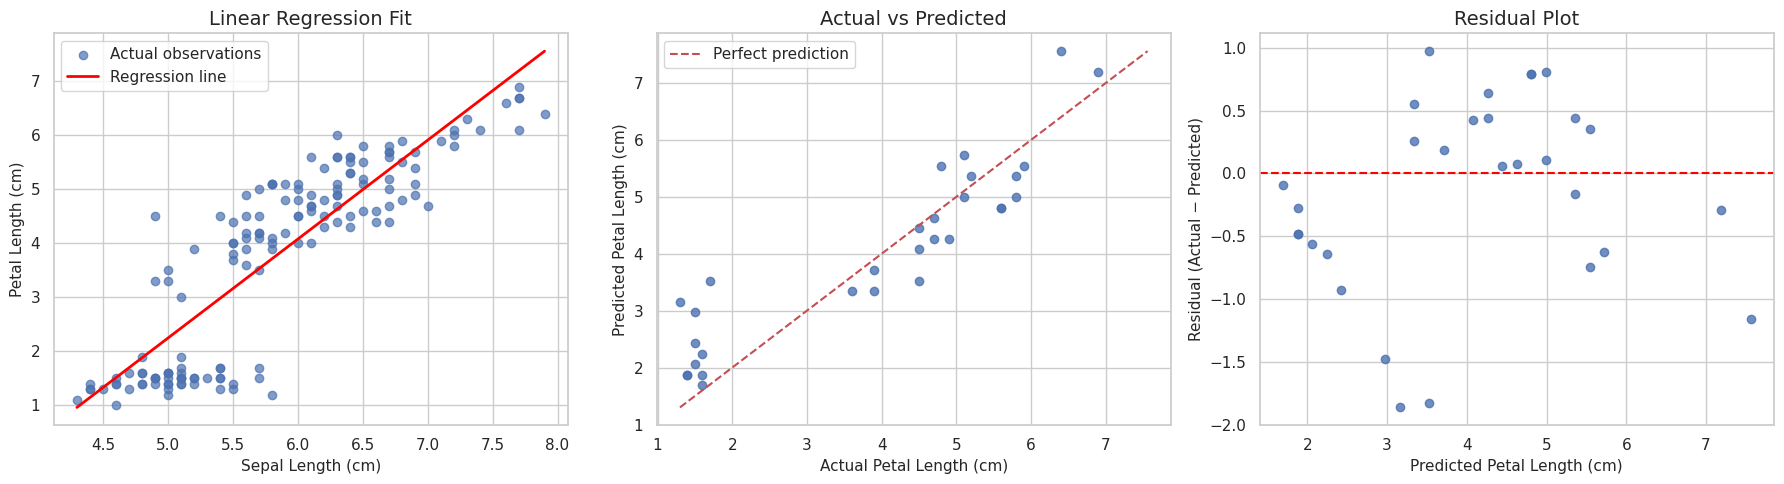


Sample predictions:


,Actual petal length,Predicted petal length,Residual
0,4.7,4.261,0.439
1,1.7,3.527,-1.827
2,6.9,7.193,-0.293
3,4.5,4.077,0.423
4,4.8,5.544,-0.744
5,1.5,2.978,-1.478
6,3.6,3.344,0.256
7,5.1,5.727,-0.627
8,4.5,4.444,0.056
9,3.9,3.711,0.189


In [2]:
# 1. Linear Regression
X_lr = df[["sepal_length"]]
y_lr = df["petal_length"]

X_train, X_test, y_train, y_test = train_test_split(
    X_lr, y_lr, test_size=0.20, random_state=42
)
lr = LinearRegression()
lr.fit(X_train, y_train)
y_pred = lr.predict(X_test)

print(f"Slope: {lr.coef_[0]:.4f}")
print(f"Intercept: {lr.intercept_:.4f}")
print(f"MAE: {mean_absolute_error(y_test, y_pred):.4f}")
print(f"MSE: {mean_squared_error(y_test, y_pred):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, y_pred)):.4f}")
print(f"R² score: {r2_score(y_test, y_pred):.4f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Scatter plus fitted line
axes[0].scatter(X_lr["sepal_length"], y_lr, alpha=0.7, label="Actual observations")
line_x = np.linspace(X_lr["sepal_length"].min(), X_lr["sepal_length"].max(), 200)
axes[0].plot(line_x, lr.predict(pd.DataFrame({"sepal_length": line_x})),
             color="red", linewidth=2, label="Regression line")
axes[0].set(title="Linear Regression Fit", xlabel="Sepal Length (cm)", ylabel="Petal Length (cm)")
axes[0].legend()

# Actual vs predicted
axes[1].scatter(y_test, y_pred, alpha=0.8)
lo, hi = min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())
axes[1].plot([lo, hi], [lo, hi], "r--", label="Perfect prediction")
axes[1].set(title="Actual vs Predicted", xlabel="Actual Petal Length (cm)", ylabel="Predicted Petal Length (cm)")
axes[1].legend()

# Residuals
residuals = y_test - y_pred
axes[2].scatter(y_pred, residuals, alpha=0.8)
axes[2].axhline(0, color="red", linestyle="--")
axes[2].set(title="Residual Plot", xlabel="Predicted Petal Length (cm)", ylabel="Residual (Actual − Predicted)")

plt.tight_layout()
plt.show()

print("\nSample predictions:")
display(pd.DataFrame({
    "Actual petal length": y_test.values[:10],
    "Predicted petal length": np.round(y_pred[:10], 3),
    "Residual": np.round(residuals.values[:10], 3)
}))
